# Risk-Model Revisions: Reading Barra's Second Thoughts
### Battle of the Quants 2026 · Initial submission

**Strategy in one sentence.** Each month, hold a little more of the stocks whose Barra risk forecasts are falling and a little less of those whose forecasts are rising, while matching the benchmark's beta, staying fully invested and long-only, and keeping tracking error at 5%.

**Why it should work.** Barra's predicted beta comes from a *fundamental* risk model (leverage, earnings variability, size and other company characteristics), while historical beta only reflects past price moves. When Barra raises a stock's forward-looking risk, or its forecast sits above what history shows, the company's fundamentals are typically deteriorating before its price behavior shows it. Investors anchor on the past and absorb that slowly, so these stocks tend to underperform as the deterioration is priced in. This is consistent with the documented underperformance of distressed and high-idiosyncratic-risk stocks (Campbell, Hilscher & Szilagyi 2008; Ang, Hodrick, Xing & Zhang 2006).

**Development-period results (2001 to Oct 2022, after costs, equal-weighted benchmark stand-in):**

| | |
|---|---|
| Active return | about +2.0% per year |
| Tracking error | 4.6% |
| Information ratio | 0.43 (t = 2.0) |
| Total Sharpe vs. benchmark | 0.51 vs. 0.45 |
| Realized beta | 1.03 |
| Turnover | 3.6× per year, one-way |

**Holdout (Nov 2022 – Oct 2025, never used for any decision):** about +1.1% per year after costs, tracking error 4.9%, information ratio 0.22, beta 0.98. Same direction as development, about half the size, and not statistically significant over three years alone (Section 9).

**What makes it different:**
- **Barra as the signal.** It uses Barra's own forecast revisions as alpha, rather than treating Barra's columns only as risk inputs.
- **The mandate, implemented exactly.** The optimizer is the one from the Silver Fund manual (Ch. 2–4), with every constraint enforced and verified each month.
- **An HRP-based exposure analysis.** The data has no sector labels, so we used HRP's hierarchical clustering to build our own and to measure what the portfolio is actually betting on.
- **Honest testing.** Every choice was fixed before seeing its results, all trial runs are disclosed (Section 8), and the most recent three years were held out.

## How to run

1. Put `BotQ_2026_data.parquet` (or the CSV version) in the same folder as this notebook or the folder above it. A GitHub "Download ZIP" only contains a Git LFS placeholder, so make sure you have the real file (about 0.5 GB).
2. Install the packages: `pip install polars numpy pandas scipy cvxpy matplotlib pyarrow`.
3. Run all cells. A full run takes about 15–20 minutes on a laptop.
4. **The holdout:** set `RUN_HOLDOUT = True` in the next cell **once**, after the team agrees this is the final version, then run all again.
5. **Real benchmark weights:** if market caps become available, set `MKTCAP_PATH` to the file. WRDS-style columns (MthCalDt, MthCap, CUSIP9, CUSIP, Ticker) are accepted.

In [1]:
import os, io, sys, time, zipfile, urllib.request, warnings
import numpy as np
import pandas as pd
import polars as pl
import cvxpy as cp
import matplotlib.pyplot as plt
from scipy.stats import norm, rankdata
from scipy.cluster.hierarchy import linkage, fcluster
from scipy.spatial.distance import squareform
from IPython.display import display
warnings.filterwarnings("ignore")
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
%matplotlib inline

RUN_HOLDOUT = True       # the holdout was run once, after the final version was locked
MKTCAP_PATH = None       # optional: monthly market caps for real benchmark weights
HOLDOUT_START = "2022-11-01"

# Strategy settings, all fixed in advance (none tuned on results)
TE = 0.05          # tracking-error target (mandate)
CAP = 0.01         # max overweight per stock (our position limit)
IC_ASSUMED = 0.02  # assumed information coefficient in the alpha forecast (Grinold-Kahn)
COST = 0.001       # 10 bps per unit traded
N_FACTORS = 10     # statistical factors in the risk model
LAG = 1            # trade one day after the signal date
N_CLUSTERS = 20    # HRP clusters used as data-driven "sectors"
os.makedirs("results", exist_ok=True)

## 1 · Data

The panel has one row per stock per day: price, daily return (in percent), Barra historical beta, Barra predicted beta, and Barra specific risk (annualized idiosyncratic volatility). It runs from January 2000 to October 2025, with about 2,950 stocks a day (9,162 in total), so delisted stocks are included and there is no survivorship bias.

We build:
- a dense day × stock return matrix (converted to decimals),
- month-end snapshots of price and the Barra fields, because portfolios are rebalanced at month-ends,
- the daily risk-free rate from Ken French's data library (with an approximate T-bill table as a fallback if the site can't be reached).

**Benchmark weights.** The data has no market caps, so by default the benchmark is an **equal-weighted stand-in** over the investable universe. This is our largest limitation (Section 10).

In [2]:
def find_data():
    here = os.getcwd()
    for place in [here, os.path.dirname(here)]:
        for name in ["BotQ_2026_data.parquet", "BotQ_2026_data.csv"]:
            p = os.path.join(place, name)
            if os.path.exists(p):
                if os.path.getsize(p) < 1_000_000:
                    raise ValueError(f"{p} is a Git LFS placeholder, not the data.")
                return p
    raise FileNotFoundError("Put BotQ_2026_data.parquet in this folder or the folder above it.")


def load_panel(path):
    try:
        lf = pl.scan_parquet(path); lf.collect_schema()
    except Exception:
        lf = pl.scan_csv(path, schema_overrides={"barrid": pl.Utf8, "cusip": pl.Utf8})
    names = lf.collect_schema().names()
    cols = ["barrid", "date", "price", "historical_beta", "predicted_beta", "return", "specific_risk"]
    cols += [c for c in ["ticker", "cusip"] if c in names]
    lf = lf.select(cols)
    if lf.collect_schema()["date"] == pl.Utf8:
        lf = lf.with_columns(pl.col("date").str.to_date())
    return lf.collect()


def build_arrays(df):
    dates = np.sort(df["date"].unique().to_numpy())
    ids = np.sort(df["barrid"].unique().to_numpy())
    d_idx = np.searchsorted(dates, df["date"].to_numpy())
    i_idx = np.searchsorted(ids, df["barrid"].to_numpy())
    R = np.full((len(dates), len(ids)), np.nan, dtype=np.float32)
    R[d_idx, i_idx] = (df["return"].to_numpy() / 100.0).astype(np.float32)   # percent -> decimal
    months = dates.astype("datetime64[M]")
    me = np.where(np.r_[months[1:] != months[:-1], True])[0]                # month-end trading days
    pos = -np.ones(len(dates), dtype=np.int64); pos[me] = np.arange(len(me))
    sel = pos[d_idx] >= 0
    snap = {}
    for c in ["price", "historical_beta", "predicted_beta", "specific_risk"]:
        A = np.full((len(me), len(ids)), np.nan, dtype=np.float32)
        A[pos[d_idx][sel], i_idx[sel]] = df[c].to_numpy()[sel].astype(np.float32)
        snap[c] = A
    keys = {}
    for c in ["ticker", "cusip"]:
        if c in df.columns:
            A = np.full((len(me), len(ids)), None, dtype=object)
            A[pos[d_idx][sel], i_idx[sel]] = df[c].to_numpy()[sel]
            keys[c] = A
    return dict(R=R, dates=dates, ids=ids, me=me, snap=snap, keys=keys)


def load_mktcap(path, data):
    caps = pd.read_parquet(path) if path.endswith(".parquet") else pd.read_csv(path, low_memory=False)
    caps.columns = [c.lower() for c in caps.columns]
    dcol = next(c for c in ["mthcaldt", "date"] if c in caps.columns)
    vcol = next(c for c in ["mthcap", "mktcap"] if c in caps.columns)
    caps["ym"] = pd.to_datetime(caps[dcol]).dt.to_period("M")
    def keyed(col):
        k = caps.dropna(subset=[col]).copy(); k["key"] = k[col].astype(str).str.upper().str.strip()
        t = k.set_index(["ym", "key"])[vcol]; return t[~t.index.duplicated()]
    matchers = []
    if "cusip" in data["keys"]:
        if "cusip9" in caps.columns: matchers.append((keyed("cusip9"), "cusip", 9))
        if "cusip" in caps.columns: matchers.append((keyed("cusip"), "cusip", 8))
    if "ticker" in caps.columns and "ticker" in data["keys"]:
        matchers.append((keyed("ticker"), "ticker", None))
    out = {}
    for mi, t in enumerate(data["me"]):
        ym = pd.Period(str(data["dates"][t])[:7], "M"); v = np.full(len(data["ids"]), np.nan)
        for table, key, n in matchers:
            k = data["keys"][key][mi]; miss = np.isnan(v) & pd.notna(k)
            if miss.any():
                codes = pd.Index(k[miss]).astype(str).str.upper().str.strip()
                codes = codes.str[:n] if n else codes
                v[miss] = table.reindex(pd.MultiIndex.from_arrays([[ym] * int(miss.sum()), codes])).to_numpy(dtype=float)
        out[mi] = v
    return out


def risk_free(dates):
    url = "https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/ftp/F-F_Research_Data_Factors_daily_CSV.zip"
    approx = dict(zip(range(2000, 2027), [5.8, 3.4, 1.6, 1.0, 1.4, 3.2, 4.7, 4.4, 1.4, 0.15, 0.14, 0.05, 0.09,
                                          0.06, 0.03, 0.05, 0.32, 0.93, 1.94, 2.06, 0.37, 0.04, 2.0, 5.05, 5.0, 4.2, 4.0]))
    rf = pd.Series(np.nan, index=pd.to_datetime(dates))
    try:
        z = zipfile.ZipFile(io.BytesIO(urllib.request.urlopen(url, timeout=30).read()))
        rows = [l.split(",") for l in z.read(z.namelist()[0]).decode("latin-1").splitlines()]
        kf = pd.DataFrame([r[:5] for r in rows if len(r) >= 5 and r[0].strip().isdigit() and len(r[0].strip()) == 8])
        rf = pd.Series(kf[4].astype(float).values / 100,
                       index=pd.to_datetime(kf[0].str.strip(), format="%Y%m%d")).reindex(rf.index)
        src = "Ken French data library"
    except Exception:
        src = "approximate T-bill table (Ken French site unreachable)"
    gap = rf.isna(); rf[gap] = [approx.get(d.year, 0.0) / 100 / 252 for d in rf.index[gap]]
    return rf.to_numpy(), src


t0 = time.time()
data = build_arrays(load_panel(find_data()))
R, dates, ids, me, snap = data["R"], data["dates"], data["ids"], data["me"], data["snap"]
mkt = np.nanmean(R, axis=1).astype(np.float64)   # equal-weighted panel average, used to beta-adjust test returns
hold_idx = int(np.searchsorted(dates, np.datetime64(HOLDOUT_START)))
rf, rf_src = risk_free(dates)
caps = load_mktcap(MKTCAP_PATH, data) if MKTCAP_PATH else None
print(f"{R.shape[0]:,} trading days x {R.shape[1]:,} stocks, {dates[0]} to {dates[-1]}")
print(f"Risk-free rate: {rf_src}")
print(f"Benchmark weights: {'market caps from ' + MKTCAP_PATH if caps else 'EQUAL-WEIGHTED stand-in (no market caps)'}")
print(f"Holdout starts {HOLDOUT_START}: {'INCLUDED in this run' if RUN_HOLDOUT else 'sealed'}  ({time.time() - t0:.0f}s)")

6,487 trading days x 9,162 stocks, 2000-01-03 to 2025-10-16
Risk-free rate: approximate T-bill table (Ken French site unreachable)
Benchmark weights: EQUAL-WEIGHTED stand-in (no market caps)
Holdout starts 2022-11-01: INCLUDED in this run  (9s)


## 2 · The signal (fixed before any testing)

At each month-end *t*, a stock is **eligible** if:
- its price is at least $5,
- all three Barra fields are available both at *t* and three months earlier,
- it has at least 200 daily returns in the past year.

That leaves about 2,500 stocks.

Three clues that a stock's risk is rising, each converted to a percentile rank across stocks:
1. **3-month change in Barra predicted beta.**
2. **3-month change in Barra specific risk.**
3. **Predicted beta minus historical beta:** Barra sees more market risk ahead than history shows.

**Signal = −(average of the three ranks).** A high score means risk is calming down, and we expect those stocks to do better.

For testing, we also compute:
- **Known effects as controls:** last-month return, 12-1 momentum, 1-year volatility, beta, specific risk, and the largest one-day gain last month.
- **Two rival signals we tested and rejected:** lottery avoidance and news-shock drift.
- **Forward returns:** beta-adjusted, starting two trading days after *t* (one-day trading lag), and never extending into the holdout.

In [3]:
def prank(x):
    return (rankdata(x) - 0.5) / len(x)


def universe_and_signal(mi, S=None):
    # Eligible stocks at month-end mi, the revision signal, last month's return spread, Barra beta.
    # S lets us swap in Barra values from a different date (used in the timing robustness check).
    S = snap if S is None else S
    t = me[mi]; s = {k: v[mi] for k, v in S.items()}; s3 = {k: v[mi - 3] for k, v in S.items()}
    year = R[t - 251:t + 1]
    U = np.where((s["price"] >= 5) & np.isfinite(s["predicted_beta"]) & np.isfinite(s["specific_risk"])
                 & np.isfinite(s["historical_beta"]) & np.isfinite(s3["predicted_beta"])
                 & np.isfinite(s3["specific_risk"]) & ((~np.isnan(year)).sum(0) >= 200) & ~np.isnan(R[t]))[0]
    dbeta = (s["predicted_beta"] - s3["predicted_beta"])[U]
    dsr = (s["specific_risk"] - s3["specific_risk"])[U]
    gap = (s["predicted_beta"] - s["historical_beta"])[U]
    signal = -(prank(dbeta) + prank(dsr) + prank(gap)) / 3
    last_month = np.prod(1 + np.nan_to_num(R[t - 20:t + 1, U].astype(np.float64)), 0) - 1
    return U, signal, float(np.std(last_month)), s["predicted_beta"][U].astype(float), (dbeta, dsr, gap)


def signal_rows(mi):
    U, sig, _, beta, (dbeta, dsr, gap) = universe_and_signal(mi)
    t = me[mi]; Y = np.nan_to_num(R[t - 251:t + 1, U].astype(np.float64))
    o = dict(mi=mi, stock=U, sig_revision=sig, dbeta=dbeta, dsrisk=dsr, betagap=gap)
    srisk = snap["specific_risk"][mi][U].astype(float)
    max1m = Y[-21:].max(0); vol1y = R[t - 251:t + 1, U].astype(np.float64); vol1y = np.nanstd(vol1y, 0)
    o["sig_lottery"] = -(prank(max1m) + prank(srisk) + prank(vol1y)) / 3          # rejected idea 1
    E = R[t - 314:t - 62, U].astype(np.float64); m_ = mkt[t - 314:t - 62]; ok = ~np.isnan(E)
    md_ = m_ - m_.mean(); Ed = np.where(ok, E - np.nanmean(E, 0), 0.0); bb = (md_ @ Ed) / (md_ @ md_)
    rsd = np.sqrt(np.nanmean(np.where(ok, (E - np.nanmean(E, 0) - np.outer(md_, bb)) ** 2, np.nan), 0))
    z = np.nan_to_num((R[t - 62:t + 1, U].astype(np.float64) - np.outer(mkt[t - 62:t + 1], bb)) / rsd)
    o["sig_news"] = (z * (np.abs(z) > 3)).sum(0)                                     # rejected idea 2
    o.update(c_rev1m=np.prod(1 + Y[-21:], 0) - 1, c_mom12_1=np.prod(1 + Y[:-21], 0) - 1, c_vol1y=vol1y,
             c_beta=beta, c_srisk=srisk, c_max1m=max1m, price=snap["price"][mi][U].astype(float),
             zero_days=(R[t - 62:t + 1, U] == 0).mean(0))
    st = t + 1 + LAG
    for name, h in [("fwd_1w", 5), ("fwd_1m", 21), ("fwd_3m", 63)]:
        if st + h > hold_idx:
            o[name] = np.full(len(U), np.nan); continue
        r = np.prod(1 + np.nan_to_num(R[st:st + h, U].astype(np.float64)), 0) - 1
        o[name] = r - beta * (np.prod(1 + mkt[st:st + h]) - 1)                      # beta-adjusted
    return pd.DataFrame(o)


dev_months = [mi for mi in range(len(me)) if mi >= 4 and me[mi] >= 320 and dates[me[mi]] < np.datetime64(HOLDOUT_START)]
SP = pd.concat([signal_rows(mi) for mi in dev_months], ignore_index=True)
SP["date"] = dates[me[SP.mi.values]]
print(f"{SP.mi.nunique()} months, {len(SP):,} stock-months, {SP.groupby('mi').size().median():.0f} stocks per month (median)")

259 months, 651,098 stock-months, 2554 stocks per month (median)


## 3 · Does the signal predict returns?

Three tests, each run every month and then averaged:
- **IC:** the rank correlation between the signal and next-period beta-adjusted returns.
- **Quintile spread:** the return of the top 20% of stocks minus the bottom 20%. Split in two, it shows whether the edge sits in the stocks to overweight (top minus average, the **long side**) or the stocks to avoid (average minus bottom, the **short side**). That matters under long-only.
- **Fama–MacBeth regressions:** does the signal still predict returns after controlling for known effects?

t-statistics use Newey–West standard errors, which correct for overlapping horizons.

In [4]:
def nw_t(x, lags=1):
    x = np.asarray(x, float); x = x[~np.isnan(x)]; n = len(x); m = x.mean(); e = x - m; v = (e @ e) / n
    for l in range(1, lags + 1):
        v += 2 * (1 - l / (lags + 1)) * (e[l:] @ e[:-l]) / n
    return m / np.sqrt(v / n)


def monthly_stats(df, sig, ret):
    ic, sp, lo, sh = [], [], [], []
    for _, g in df[["date", sig, ret]].dropna().groupby("date"):
        ic.append(g[sig].rank().corr(g[ret].rank()))
        q = pd.qcut(g[sig].rank(method="first"), 5, labels=False); mu = g[ret].mean()
        a, b = g[ret][q == 4].mean(), g[ret][q == 0].mean()
        sp.append(a - b); lo.append(a - mu); sh.append(mu - b)
    return [np.array(x) for x in (ic, sp, lo, sh)]


def fama_macbeth(df, cols, ret="fwd_1m"):
    co = []
    for _, g in df[["date", ret] + cols].dropna().groupby("date"):
        X = g[cols].rank(pct=True).values - 0.5; X = np.column_stack([np.ones(len(X)), X / X.std(0)])
        co.append(np.linalg.lstsq(X, g[ret].values, rcond=None)[0][1])
    co = np.array(co); return 100 * co.mean(), nw_t(co)


rows = []
for hn, lags in [("1w", 1), ("1m", 1), ("3m", 3)]:
    ic, sp, lo, sh = monthly_stats(SP, "sig_revision", f"fwd_{hn}")
    rows.append({"horizon": hn, "IC": ic.mean(), "IC t": nw_t(ic, lags), "top-bottom %": 100 * sp.mean(),
                 "t ": nw_t(sp, lags), "long side %": 100 * lo.mean(), "t  ": nw_t(lo, lags),
                 "short side %": 100 * sh.mean(), "t   ": nw_t(sh, lags)})
print("Revision signal vs. future beta-adjusted returns (returns are per period, not annualized)")
display(pd.DataFrame(rows).set_index("horizon").round(4))

Revision signal vs. future beta-adjusted returns (returns are per period, not annualized)


,IC,IC t,top-bottom %,t,long side %,t,short side %,t
horizon,,,,,,,,
1w,0.0105,1.9407,0.0449,0.4971,0.0426,1.0341,0.0023,0.0424
1m,0.0187,3.7010,0.4292,2.9007,0.1634,2.0766,0.2659,3.3929
3m,0.0263,3.8952,1.1070,2.9323,0.4192,2.1669,0.6878,3.2968


In [5]:
print("Which clues carry the signal? (1-month IC; negative = rising risk predicts lower returns)")
comp = []
for c, lab in [("dbeta", "3-month change in predicted beta"), ("dsrisk", "3-month change in specific risk"),
               ("betagap", "predicted minus historical beta")]:
    ic, _, _, _ = monthly_stats(SP, c, "fwd_1m"); comp.append({"clue": lab, "IC": ic.mean(), "t": nw_t(ic)})
display(pd.DataFrame(comp).set_index("clue").round(4))

print("Stability over time (1-month IC)")
sub = []
for lo_, hi_ in [("2001", "2007-12-31"), ("2008", "2014-12-31"), ("2015", "2022-12-31")]:
    ic, _, _, _ = monthly_stats(SP[(SP.date >= lo_) & (SP.date <= hi_)], "sig_revision", "fwd_1m")
    sub.append({"period": f"{lo_}-{hi_[:4]}", "IC": ic.mean(), "t": nw_t(ic)})
display(pd.DataFrame(sub).set_index("period").round(4))

Which clues carry the signal? (1-month IC; negative = rising risk predicts lower returns)


,IC,t
clue,,
3-month change in predicted beta,-0.0169,-2.8239
3-month change in specific risk,0.0044,1.1237
predicted minus historical beta,-0.0246,-3.9368


Stability over time (1-month IC)


,IC,t
period,,
2001-2007,0.0141,1.8816
2008-2014,0.0027,0.2990
2015-2022,0.0373,4.2556


**Is it just a known effect in disguise?** The table compares our signal with the two rejected rivals. The key row for the mandate is **lottery + beta**: lottery avoidance is the strongest raw signal in the data, but controlling for beta erases it. Because the mandate fixes beta at 1, that edge isn't available to us. The revision signal keeps its predictive power after every control.

In [6]:
base = ["c_rev1m", "c_mom12_1", "c_beta"]; risk = ["c_vol1y", "c_srisk", "c_max1m"]
specs = [("Revision", ["sig_revision"]), ("Revision + reversal, momentum, beta", ["sig_revision"] + base),
         ("Revision + all controls (adds vol, specific risk, max)", ["sig_revision"] + base + risk),
         ("Lottery avoidance", ["sig_lottery"]), ("Lottery + beta", ["sig_lottery", "c_beta"]),
         ("News-shock drift", ["sig_news"]), ("News drift + all controls", ["sig_news"] + base + risk)]
fm = []
for lab, cols in specs:
    c, t_ = fama_macbeth(SP, cols); fm.append({"regression (first variable is tested)": lab,
                                               "coef, % per month per 1 sd": c, "t": t_})
display(pd.DataFrame(fm).set_index("regression (first variable is tested)").round(3))

,"coef, % per month per 1 sd",t
regression (first variable is tested),,
Revision,0.148,2.897
"Revision + reversal, momentum, beta",0.086,1.916
"Revision + all controls (adds vol, specific risk, max)",0.085,2.029
Lottery avoidance,0.343,4.441
Lottery + beta,0.043,0.439
News-shock drift,-0.023,-0.638
News drift + all controls,-0.016,-0.609


**Mechanism test.** If slow reaction drives the signal, it should be stronger in stocks that get less attention. Two proxies are available in the data: a low share price and frequent zero-return days (illiquidity). The table also answers a common objection: *does it work only in tiny, untradeable stocks?*

In [7]:
mech = []
for proxy, lab in [("price", "share price"), ("zero_days", "zero-return days")]:
    res = {0: [], 1: [], 2: []}
    for _, g in SP.dropna(subset=["fwd_1m"]).groupby("date"):
        q = pd.qcut(g[proxy].rank(method="first"), 3, labels=False)
        for k in range(3):
            gg = g[q == k]; res[k].append(gg.sig_revision.rank().corr(gg.fwd_1m.rank()))
    r = [np.array(res[k]) for k in range(3)]
    for k, name in enumerate(["low third", "middle third", "high third"]):
        mech.append({"split by": lab, "group": name, "IC": r[k].mean(), "t": nw_t(r[k])})
    mech.append({"split by": lab, "group": "high minus low", "IC": r[2].mean() - r[0].mean(), "t": nw_t(r[2] - r[0])})
display(pd.DataFrame(mech).set_index(["split by", "group"]).round(4))

IC       t
split by         group                         
share price      low third       0.0242  4.9275
                 middle third    0.0132  2.3724
                 high third      0.0156  2.6334
                 high minus low -0.0086 -1.6585
zero-return days low third       0.0178  3.2622
                 middle third    0.0208  3.7835
                 high third      0.0163  3.1576
                 high minus low -0.0015 -0.4245

## 4 · Portfolio construction under the mandate

Each month we choose active weights *h* (the portfolio = benchmark + *h*). This follows the Silver Fund manual, Ch. 2–4:

$$\max_h \; \alpha^\top h \;-\; c\,\lVert h - h_{\text{prev}}\rVert_1$$

subject to:

| Constraint | Meaning |
|---|---|
| $\iota^\top h = 0$ | Zero investment: the portfolio stays fully invested |
| $\beta_{\text{Barra}}^\top h = 0$ | Unit beta: the portfolio's beta equals the benchmark's |
| $\sqrt{h^\top V h} \le 5\%$ | Tracking-error target |
| $b + h \ge 0$ | Long-only |
| $h \le 1\%$ | Position limit (our assumption) |

The pieces:
- **Alpha forecast (manual Ch. 4, Grinold–Kahn):** $\alpha_i = \text{IC}\cdot\sigma_r\cdot Z_i$. Here $Z$ is the signal mapped to a standard normal score, $\sigma_r$ is the cross-sectional spread of last month's returns, and IC is fixed at 0.02, not fitted.
- **Risk model *V*:** 10 statistical factors (PCA) from the past year of daily returns, plus **Barra's forecast of each stock's specific risk**. It is forward-looking, which matters because the signal itself is about changing risk.
- **Trading penalty:** *c* = 10 bps per unit traded. The optimizer trades only when the expected gain beats the cost.
- **Beta:** Barra's forward-looking predicted beta. An earlier build that used return-based betas drifted to a realized beta of 0.89.

**How this maps to the competition deck.** The deck asks for an active portfolio with **0 beta, 0 weight, and 5% active yearly volatility**, which are the first three constraints. **Long-only** and the **1% position limit** are our own choices, made to keep the portfolio realistic and conservative. They are not required by the deck, and relaxing long-only is a natural next step, because the signal's edge is somewhat stronger on the "stocks to avoid" side.

Each month we also cluster the stocks with HRP's correlation distance (Section 6) and solve a **cluster-neutral** version, used later to measure the portfolio's exposures.

In [8]:
def nscore(x):
    z = norm.ppf(prank(x)); return (z - z.mean()) / z.std()


def risk_model(X, k=N_FACTORS):
    X = np.nan_to_num(X - np.nanmean(X, 0)); _, _, Vt = np.linalg.svd(X, full_matrices=False)
    B = Vt[:k].T; f = X @ B
    return B, np.cov(f, rowvar=False) * 252


def te_of(h, B, F, D):
    y = B.T @ h; return float(np.sqrt(y @ F @ y + (h ** 2) @ D))


def optimize(Z, B, F, D, b, beta, h_prev, sigma_r, groups=None):
    N = len(Z); alpha = IC_ASSUMED * sigma_r * Z
    L = np.linalg.cholesky(F + 1e-12 * np.eye(F.shape[0])); h = cp.Variable(N)
    risk = cp.hstack([L.T @ (B.T @ h), cp.multiply(np.sqrt(D), h)])
    cons = [cp.sum(h) == 0, beta @ h == 0, h >= -b, h <= CAP, cp.norm(risk, 2) <= TE]
    if groups is not None:                       # cluster-neutral: zero active weight in every cluster
        G = np.zeros((N_CLUSTERS, N)); G[groups - 1, np.arange(N)] = 1; cons.append(G @ h == 0)
    prob = cp.Problem(cp.Maximize(alpha @ h - COST * cp.norm1(h - h_prev)), cons)
    prob.solve(solver=cp.CLARABEL)
    if prob.status not in ("optimal", "optimal_inaccurate"):
        raise RuntimeError(prob.status)
    return np.asarray(h.value).ravel()


def hrp_clusters(X):
    # HRP's correlation distance on market-residual returns, Ward linkage, cut into N_CLUSTERS groups.
    Xd = np.nan_to_num(X - np.nanmean(X, 0)); _, _, Vt = np.linalg.svd(Xd, full_matrices=False)
    res = Xd - np.outer(Xd @ Vt[0], Vt[0]); sd = res.std(0); sd[sd == 0] = 1
    C = np.nan_to_num(np.corrcoef((res / sd).T)); Dm = np.sqrt(np.clip(0.5 * (1 - C), 0, None))
    np.fill_diagonal(Dm, 0)
    return fcluster(linkage(squareform(Dm, checks=False), "ward"), N_CLUSTERS, "maxclust")

In [9]:
def bench_weights(mi, U):
    if caps is not None:
        c = caps[mi][U]; b = np.where(np.isfinite(c), c, 0.0); return b / b.sum()
    return np.full(len(U), 1 / len(U))


t0 = time.time()
last_mi = len(me) - 1 if RUN_HOLDOUT else int(np.searchsorted(me, hold_idx)) - 1
positions = {"Strategy": {}, "Cluster-neutral": {}}
prev = {k: pd.Series(dtype=float) for k in positions}
clusters, checks = {}, []
for mi in range(len(me)):
    if mi < 4 or me[mi] < 320 or mi > last_mi:
        continue
    U, sig, sigma_r, beta, _ = universe_and_signal(mi); t = me[mi]; N = len(U)
    b = bench_weights(mi, U)
    X = R[t - 251:t + 1, U].astype(np.float64)
    B, F = risk_model(X); D = (snap["specific_risk"][mi][U].astype(float) / 100) ** 2
    Z = nscore(sig)
    h = optimize(Z, B, F, D, b, beta, prev["Strategy"].reindex(U).fillna(0).values, sigma_r)
    positions["Strategy"][mi] = (U, h, b); prev["Strategy"] = pd.Series(h, index=U)
    in_dev = dates[t] < np.datetime64(HOLDOUT_START)
    g = hrp_clusters(X) if in_dev else None
    if in_dev:
        hc = optimize(Z, B, F, D, b, beta, prev["Cluster-neutral"].reindex(U).fillna(0).values, sigma_r, groups=g)
        positions["Cluster-neutral"][mi] = (U, hc, b); prev["Cluster-neutral"] = pd.Series(hc, index=U)
        clusters[mi] = g
    cl = pd.Series(h).groupby(g).sum() if g is not None else pd.Series([np.nan])
    checks.append({"date": dates[t], "sum of active weights": h.sum(), "active Barra beta": beta @ h,
                   "ex-ante tracking error": te_of(h, B, F, D), "lowest portfolio weight": (b + h).min(),
                   "largest overweight": h.max(), "stocks held": int(((b + h) > 1e-6).sum()),
                   "stocks overweighted": int((h > 1e-6).sum()),
                   "gross cluster bet": cl.abs().sum(), "largest cluster bet": cl.abs().max()})
    if mi % 36 == 0:
        print(f"  built {dates[t]}  ({time.time() - t0:.0f}s)", flush=True)
CK = pd.DataFrame(checks).set_index("date")
print(f"Built {len(positions['Strategy'])} monthly portfolios in {time.time() - t0:.0f}s")

  built 2003-01-31  (11s)


  built 2006-01-31  (31s)


  built 2009-01-30  (52s)


  built 2012-01-31  (71s)


  built 2015-01-30  (94s)


  built 2018-01-31  (117s)


  built 2021-01-29  (140s)


  built 2024-01-31  (156s)


Built 295 monthly portfolios in 160s


**Every constraint, checked every month.** The worst case across all months is shown. Values like 1e-15 are floating-point rounding, not violations.

In [10]:
worst = pd.Series({
    "max |sum of active weights|": CK["sum of active weights"].abs().max(),
    "max |active Barra beta|": CK["active Barra beta"].abs().max(),
    "max ex-ante tracking error": CK["ex-ante tracking error"].max(),
    "lowest portfolio weight (must be >= 0)": CK["lowest portfolio weight"].min(),
    "largest overweight (limit 1%)": CK["largest overweight"].max()})
display(worst.to_frame("worst month").style.format("{:.2e}"))
print(f"Typical portfolio: {CK['stocks held'].median():.0f} stocks held, "
      f"{CK['stocks overweighted'].median():.0f} of them overweighted (median across months)")

,worst month
max |sum of active weights|,3.89e-16
max |active Barra beta|,3.78e-16
max ex-ante tracking error,5.00e-02
lowest portfolio weight (must be >= 0),-5.88e-11
largest overweight (limit 1%),1.00e-02


Typical portfolio: 398 stocks held, 124 of them overweighted (median across months)


## 5 · Performance (development period, after costs)

The deck's requested outputs: active and total returns, Sharpe ratio, yearly volatility and return, log drawdowns, lag, leverage, and rebalance rate.

Mechanics:
- Trades happen at the close one day after the signal; returns are earned from the next day until the next rebalance.
- Active return = $h^\top r$, charged 10 bps per unit traded.
- The benchmark return is $b^\top r$.

,Development 2001 - Oct 2022
"Active return (annual, after costs)",1.99%
Tracking error (annual),4.61%
Information ratio,0.43
t-stat of active return,2.00
Worst active drawdown (log),-20.6%
Total return (annual),13.84%
Total volatility (annual),24.58%
Total Sharpe ratio,0.51
Benchmark Sharpe ratio,0.45
Worst total drawdown (log),-88.7%


,Active return %,Tracking error %,Benchmark return %,Total return %,Total volatility %
2001,3.50,3.93,3.66,7.37,21.40
2002,-4.40,4.71,-18.54,-22.41,26.39
2003,3.51,3.29,46.91,51.90,17.91
2004,-2.66,3.71,19.73,16.41,16.33
2005,3.89,3.51,7.15,11.17,15.28
2006,8.66,4.54,17.01,26.69,17.56
2007,11.06,4.91,-2.06,8.65,20.09
2008,0.62,5.95,-35.16,-34.89,47.75
2009,-9.70,4.50,36.53,23.29,36.57
2010,-0.88,3.46,27.47,25.91,24.96


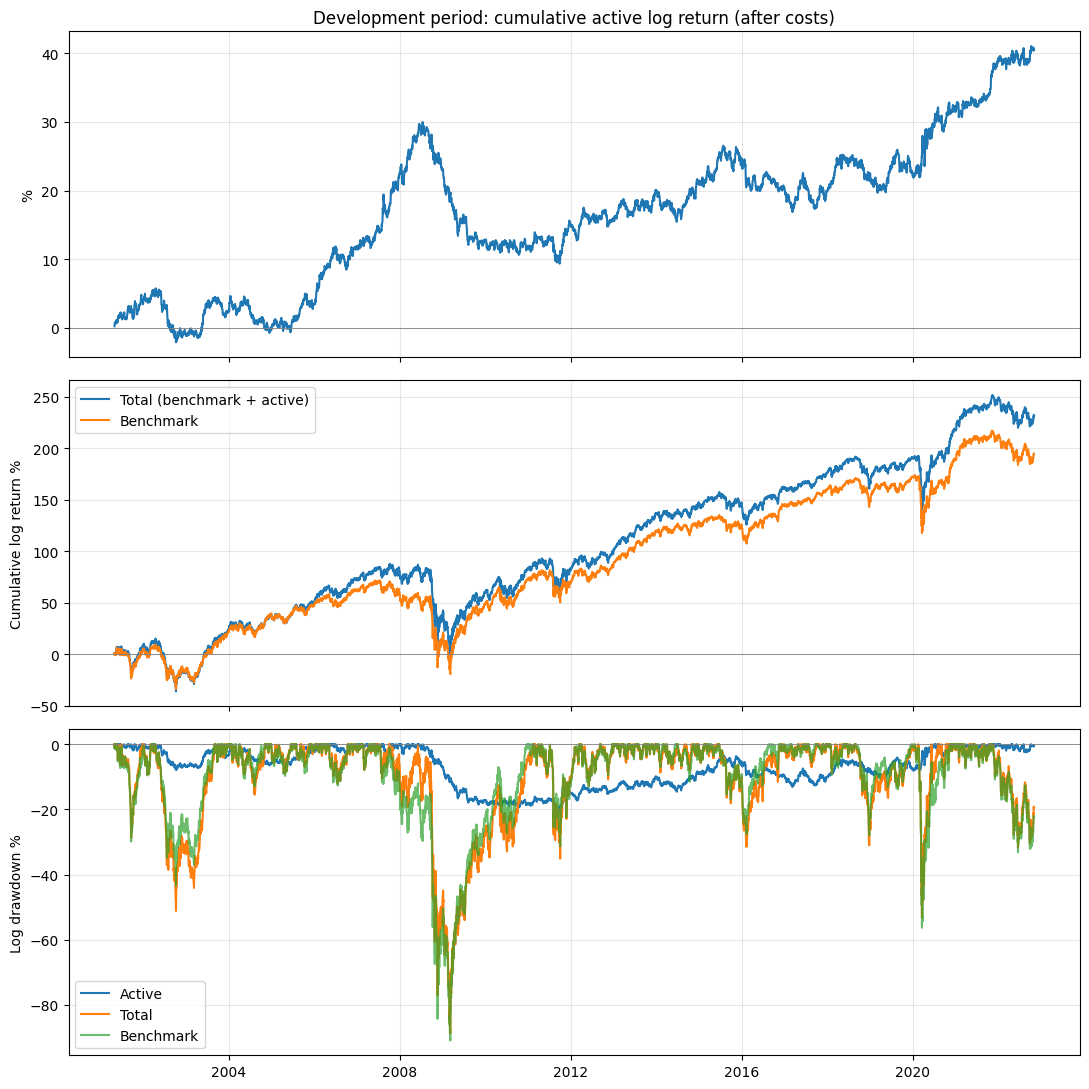

In [11]:
def backtest(pos, end_idx, cost=COST):
    T = len(dates); act, bench, live = np.zeros(T), np.zeros(T), np.zeros(T, bool)
    turnover, prv = [], pd.Series(dtype=float); keys = sorted(pos)
    for j, mi in enumerate(keys):
        U, h, b = pos[mi]; s = me[mi] + 1 + LAG
        e = min(me[keys[j + 1]] + 1 + LAG if j + 1 < len(keys) else T, end_idx)
        if s >= e: continue
        r = np.nan_to_num(R[s:e][:, U].astype(np.float64))
        act[s:e] = r @ h; bench[s:e] = r @ b; live[s:e] = True
        cur = pd.Series(h, index=U); to = cur.subtract(prv, fill_value=0).abs().sum()
        turnover.append(to); prv = cur; act[s] -= cost * to
    return act[live], bench[live], dates[live], rf[live], np.array(turnover)


def summary(a, b, f, turnover):
    ann, vol = (lambda x: x.mean() * 252), (lambda x: x.std() * np.sqrt(252)); tot = a + b; bb = b - b.mean()
    def mdd(r):
        c = np.cumsum(np.log1p(r)); return (c - np.maximum.accumulate(np.r_[0, c])[1:]).min()
    return pd.Series({
        "Active return (annual, after costs)": f"{100 * ann(a):.2f}%",
        "Tracking error (annual)": f"{100 * vol(a):.2f}%",
        "Information ratio": f"{ann(a) / vol(a):.2f}",
        "t-stat of active return": f"{ann(a) / vol(a) * np.sqrt(len(a) / 252):.2f}",
        "Worst active drawdown (log)": f"{100 * mdd(a):.1f}%",
        "Total return (annual)": f"{100 * ann(tot):.2f}%",
        "Total volatility (annual)": f"{100 * vol(tot):.2f}%",
        "Total Sharpe ratio": f"{ann(tot - f) / vol(tot):.2f}",
        "Benchmark Sharpe ratio": f"{ann(b - f) / vol(b):.2f}",
        "Worst total drawdown (log)": f"{100 * mdd(tot):.1f}%",
        "Realized beta to benchmark": f"{(tot - tot.mean()) @ bb / (bb @ bb):.2f}",
        "Turnover (one-way, per year)": f"{turnover[1:].mean() * 12 / 2:.1f}x",
        "Lag": f"{LAG} trading day after the signal date",
        "Leverage": "none (long-only, fully invested)",
        "Rebalance": "monthly"})


def yearly(a, b, d):
    df = pd.DataFrame({"a": a, "b": b, "t": a + b}, index=pd.to_datetime(d)); g = df.groupby(df.index.year)
    comp = lambda x: 100 * np.expm1(np.log1p(x).sum())
    return pd.DataFrame({"Active return %": g["a"].apply(comp), "Tracking error %": 100 * g["a"].std() * np.sqrt(252),
                         "Benchmark return %": g["b"].apply(comp), "Total return %": g["t"].apply(comp),
                         "Total volatility %": 100 * g["t"].std() * np.sqrt(252)}).round(2)


def charts(a, b, d, title, path):
    d = pd.to_datetime(d); tot = a + b
    cum = lambda r: 100 * np.cumsum(np.log1p(r))
    dd = lambda r: cum(r) - np.maximum.accumulate(np.r_[0, cum(r)])[1:]
    fig, ax = plt.subplots(3, 1, figsize=(11, 11), sharex=True)
    ax[0].plot(d, cum(a)); ax[0].set_title(f"{title}: cumulative active log return (after costs)"); ax[0].set_ylabel("%")
    ax[1].plot(d, cum(tot), label="Total (benchmark + active)"); ax[1].plot(d, cum(b), label="Benchmark")
    ax[1].set_ylabel("Cumulative log return %"); ax[1].legend()
    ax[2].plot(d, dd(a), label="Active"); ax[2].plot(d, dd(tot), label="Total"); ax[2].plot(d, dd(b), label="Benchmark", alpha=0.7)
    ax[2].set_ylabel("Log drawdown %"); ax[2].legend()
    for x in ax: x.grid(alpha=0.3); x.axhline(0, color="grey", lw=0.6)
    plt.tight_layout(); plt.savefig(path, dpi=90); plt.show()


dev_pos = {mi: p for mi, p in positions["Strategy"].items() if me[mi] + 1 + LAG < hold_idx}
a, b, d, f, to = backtest(dev_pos, hold_idx)
SUM = summary(a, b, f, to).to_frame("Development 2001 - Oct 2022")
display(SUM)
YR = yearly(a, b, d); display(YR)
SUM.to_csv("results/summary.csv"); YR.to_csv("results/yearly.csv")
charts(a, b, d, "Development period", "results/charts_development.png")

Note: drawdowns are in **log** terms, as the deck requests. A log drawdown of −89% equals about −59% in plain percentage terms. The total-portfolio drawdowns come from the benchmark in 2008–09, since the portfolio has beta 1.

**Trading-cost sensitivity.** The same trades charged at higher costs. The signal is strongest in cheaper stocks, where 10 bps may understate real costs.

In [12]:
cs = []
for c_ in [0.0, 0.001, 0.002, 0.003]:
    a_, b_, _, f_, to_ = backtest(dev_pos, hold_idx, cost=c_)
    s_ = summary(a_, b_, f_, to_)
    cs.append({"cost per unit traded": f"{c_ * 1e4:.0f} bps", "active return": s_["Active return (annual, after costs)"],
               "information ratio": s_["Information ratio"], "t-stat": s_["t-stat of active return"]})
display(pd.DataFrame(cs).set_index("cost per unit traded"))

,active return,information ratio,t-stat
cost per unit traded,,,
0 bps,2.72%,0.59,2.74
10 bps,1.99%,0.43,2.00
20 bps,1.27%,0.27,1.27
30 bps,0.54%,0.12,0.53


**Reading it:** the strategy is cost-sensitive. The IR falls from 0.59 with no costs to 0.43 at 10 bps, 0.27 at 20 bps, and 0.12 at 30 bps. Large, liquid stocks typically cost under 10 bps to trade, while small, cheap ones cost more, and the signal is somewhat stronger in cheaper stocks (Section 3). Realistic execution, meaning trading the less liquid names patiently or excluding the costliest ones, matters for capturing the edge.

**Robustness: what if the Barra data arrives late?** The deck requires data to be lagged for practical delays in receiving it. The strategy already trades one day after the signal date. Here we rebuild it using Barra values from **five trading days before** each month-end, still trading at the same time, to check whether the edge depends on getting Barra data quickly.

In [13]:
K = 5
t0 = time.time()
raw = load_panel(find_data())
d_idx = np.searchsorted(dates, raw["date"].to_numpy()); i_idx = np.searchsorted(ids, raw["barrid"].to_numpy())
lag_days = me - K; okd = lag_days >= 0
pos_ = -np.ones(len(dates), dtype=np.int64); pos_[lag_days[okd]] = np.arange(len(me))[okd]
sel = pos_[d_idx] >= 0
snap_lag = {"price": snap["price"]}          # price and returns stay at the month-end
for c in ["historical_beta", "predicted_beta", "specific_risk"]:
    A = np.full((len(me), len(ids)), np.nan, dtype=np.float32)
    A[pos_[d_idx][sel], i_idx[sel]] = raw[c].to_numpy()[sel].astype(np.float32); snap_lag[c] = A
del raw
lag_pos, prv = {}, pd.Series(dtype=float)
for mi in sorted(dev_pos):
    U, sig, sigma_r, beta, _ = universe_and_signal(mi, snap_lag); t = me[mi]; b = bench_weights(mi, U)
    B, F = risk_model(R[t - 251:t + 1, U].astype(np.float64))
    D = (snap_lag["specific_risk"][mi][U].astype(float) / 100) ** 2
    h = optimize(nscore(sig), B, F, D, b, beta, prv.reindex(U).fillna(0).values, sigma_r)
    lag_pos[mi] = (U, h, b); prv = pd.Series(h, index=U)
a_l, b_l, d_l, f_l, to_l = backtest(lag_pos, hold_idx)
display(pd.concat([SUM.iloc[:, 0].rename("Barra at month-end (strategy)"),
                   summary(a_l, b_l, f_l, to_l).rename("Barra 5 trading days earlier")], axis=1).iloc[:12])
print(f"({time.time() - t0:.0f}s)")

,Barra at month-end (strategy),Barra 5 trading days earlier
"Active return (annual, after costs)",1.99%,2.41%
Tracking error (annual),4.61%,4.69%
Information ratio,0.43,0.51
t-stat of active return,2.00,2.38
Worst active drawdown (log),-20.6%,-20.1%
Total return (annual),13.84%,14.25%
Total volatility (annual),24.58%,24.56%
Total Sharpe ratio,0.51,0.53
Benchmark Sharpe ratio,0.45,0.45
Worst total drawdown (log),-88.7%,-85.9%


(58s)


**Reading it:** the edge survives a full week of stale Barra data. The result is in fact slightly higher, which is within normal noise. We keep the original version, because choosing a version after seeing which tested better would be tuning. The signal is built on 3-month changes in Barra's forecasts, so it moves slowly, and a few days' delay barely matters. That is consistent with the economic story and argues against a data-timing artifact.

## 6 · Where the edge comes from: an HRP exposure analysis

The deck asks teams to explain their **exposures to risk**, but the data has no sector labels. We built our own: each month, stocks are clustered with **HRP's hierarchical-clustering step** (López de Prado 2016): the correlation distance $d_{ij}=\sqrt{\tfrac12(1-\rho_{ij})}$ on market-residual returns, cut into 20 clusters. The clusters behave like industries.

With them, we:
1. **Measure the portfolio's cluster bets:** its net active weight in each group of related stocks.
2. **Split the active return** into *group-level bets* (leaning into or away from whole clusters) and *stock selection within clusters*. This is a Brinson-style attribution, before costs.
3. **Re-run the strategy with every cluster bet forced to zero,** to test whether the group-level bets add value.

We also tested HRP as the portfolio builder itself (Section 8). It underperformed the optimizer, because HRP is designed for diversification rather than for expressing a signal under a tracking-error budget. Its clustering, however, is the right tool for this analysis.

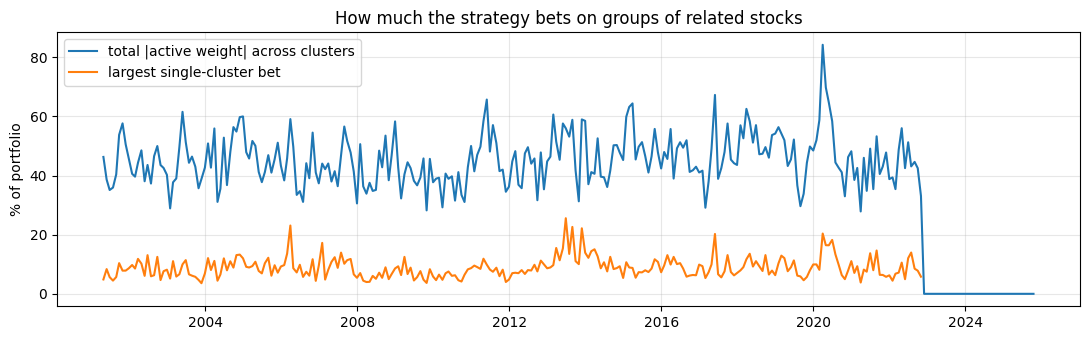

,annual return %,t-stat
group-level bets (cluster allocation),0.48,1.00
stock selection within clusters,2.24,2.70
"total active, before costs",2.72,2.74


,Strategy,Cluster-neutral (HRP clusters)
"Active return (annual, after costs)",1.99%,1.02%
Tracking error (annual),4.61%,3.98%
Information ratio,0.43,0.26
t-stat of active return,2.00,1.19
Worst active drawdown (log),-20.6%,-21.8%
Total return (annual),13.84%,12.87%
Total volatility (annual),24.58%,24.64%
Total Sharpe ratio,0.51,0.47
Benchmark Sharpe ratio,0.45,0.45
Worst total drawdown (log),-88.7%,-83.2%


In [14]:
fig, ax = plt.subplots(figsize=(11, 3.5))
ax.plot(pd.to_datetime(CK.index), 100 * CK["gross cluster bet"], label="total |active weight| across clusters")
ax.plot(pd.to_datetime(CK.index), 100 * CK["largest cluster bet"], label="largest single-cluster bet")
ax.set_ylabel("% of portfolio"); ax.set_title("How much the strategy bets on groups of related stocks"); ax.grid(alpha=0.3); ax.legend()
plt.tight_layout(); plt.savefig("results/cluster_bets.png", dpi=90); plt.show()

# Attribution: group-level bets vs. stock selection within clusters (before costs)
alloc, select = [], []
keys = sorted(clusters)
for j, mi in enumerate(keys):
    U, h, b = positions["Strategy"][mi]; g = clusters[mi]; s = me[mi] + 1 + LAG
    e = min(me[keys[j + 1]] + 1 + LAG if j + 1 < len(keys) else len(dates), hold_idx)
    if s >= e: continue
    r = np.nan_to_num(R[s:e][:, U].astype(np.float64)); rb = r @ b
    Hc = pd.Series(h).groupby(g).sum()
    rc = pd.DataFrame(r).T.groupby(g).apply(lambda x: x.mul(b[x.index], axis=0).sum() / b[x.index].sum()).T
    al = (rc.values - rb[:, None]) @ Hc.reindex(rc.columns).values
    alloc.append(al); select.append(r @ h - al)
alloc, select = np.concatenate(alloc), np.concatenate(select)
att = pd.DataFrame({"annual return %": [100 * 252 * alloc.mean(), 100 * 252 * select.mean(), 100 * 252 * (alloc + select).mean()],
                    "t-stat": [alloc.mean() / alloc.std() * np.sqrt(len(alloc)), select.mean() / select.std() * np.sqrt(len(select)),
                               (alloc + select).mean() / (alloc + select).std() * np.sqrt(len(alloc))]},
                   index=["group-level bets (cluster allocation)", "stock selection within clusters", "total active, before costs"])
display(att.round(2))

a_c, b_c, d_c, f_c, to_c = backtest(positions["Cluster-neutral"], hold_idx)
cmp_ = pd.concat([SUM.iloc[:, 0].rename("Strategy"), summary(a_c, b_c, f_c, to_c).rename("Cluster-neutral (HRP clusters)")], axis=1)
display(cmp_.iloc[:12])

In [15]:
# What the clusters look like: the most recent development month
mi_last = max(clusters); U, h, b = positions["Strategy"][mi_last]; g = clusters[mi_last]
tick = data["keys"]["ticker"][mi_last][U] if "ticker" in data["keys"] else np.array([""] * len(U))
srisk = snap["specific_risk"][mi_last][U]
rows = []
for c in np.unique(g):
    m = g == c; order = np.argsort(srisk[m])
    rows.append({"cluster": c, "stocks": int(m.sum()), "portfolio active weight %": 100 * h[m].sum(),
                 "examples (lowest specific risk)": ", ".join([str(x) for x in tick[m][order][:6]])})
print(f"Clusters at {dates[me[mi_last]]}")
display(pd.DataFrame(rows).sort_values("portfolio active weight %").set_index("cluster").round(2))

Clusters at 2022-10-31


,stocks,portfolio active weight %,examples (lowest specific risk)
cluster,,,
10,95,-3.79,"O, NNN, ROIC, PEAK, BRX, ADC"
4,168,-2.53,"CBSH, FULT, FNB, CBU, PB, NBTB"
7,57,-2.30,"SO, DUK, AEP, CMS, AEE, DTE"
5,112,-1.64,"MET, PRU, AFL, CB, BRK.B, L"
9,33,-1.33,"MAA, FR, CPT, AVB, AMH, ELS"
14,46,-1.31,"AMAT, ADI, VSH, TXN, MCHP, LRCX"
6,101,-1.08,"XOM, COP, KMI, NFG, MPC, WMB"
8,25,-1.01,"STWD, BXMT, LADR, ABR, ACRE, TRTX"
1,144,-0.79,"IRWD, MASI, BIIB, NBIX, SUPN, VNDA"


**Reading the exposure analysis:**

- **The HRP clusters look like real industries,** even though no industry data was used. In the October 2022 snapshot: REITs, regional banks, utilities, insurers, semiconductors, energy, consumer staples, defense, homebuilders, managed care and medtech, and software each form their own cluster.
- **The edge is mostly stock selection.** About +2.2% a year (t = 2.7) comes from picking stocks *within* clusters. Group-level bets add only about +0.5% a year (t = 1.0), which is not statistically significant.
- **Forcing every cluster bet to zero cuts the IR from 0.43 to 0.26.** Removing group bets alone wouldn't explain that drop. Under long-only, each cluster must then pay for its own overweights, which restricts stock selection and raises turnover. We keep the unconstrained version and monitor its cluster bets, which typically stay within a few percent of the portfolio.
- **Positioning as of October 2022:** the portfolio leans toward software and tech, managed care and medtech, and industrials, and away from REITs, regional banks, and utilities.

## 7 · Signal ideas we tested and rejected

Every alternative below was specified before seeing its results. The full code for the distance-to-centroid tests is in the `distance_to_centroid` folder of our repository.

| Idea | Best result | Why rejected |
|---|---|---|
| **Distance to cluster centroid**, two maps: correlation PCA on returns, and PCA on stock traits | IC ≈ 0.000 (t ≈ −0.1). The known effects run through the same test were detected (low volatility t = −9, momentum t = 2.8) | No predictive power. Distance ignores *direction*: stocks drifting toward more risk and toward less risk both count as "far," and their effects cancel |
| **Lottery avoidance** (max return, specific risk, volatility) | IC 0.064 (t = 9.6) | It's a beta bet. With beta controlled it disappears (Section 3), and the unit-beta mandate cancels it |
| **News-shock drift** (big stock-specific moves continue) | IC −0.007 | The moves slightly reverse instead, fully explained by short-term reversal |
| **Betting against correlation**, in an earlier zero-net, zero-beta build | IR ≈ 0.1 | The low-risk premium needs leverage, which the mandate rules out |

## 8 · Portfolio versions tested, and why this one was chosen

All on the development period, after 10 bps costs. Each change was justified before it was run.

| Version | IR | t | Note |
|---|---|---|---|
| First build: return-based beta, no cost penalty (three position limits) | 0.20–0.27 | ≈1 | Realized beta drifted to 0.89; turnover 7× per year |
| + Barra beta + trading-cost penalty | 0.42 | 1.96 | Beta 1.03, turnover halved |
| **+ Barra specific risk in the risk model (final)** | **0.43** | **2.00** | Forward-looking risk forecasts throughout |
| HRP as portfolio builder (two designs) | 0.14 / 0.22 | <1 | Diversifies the signal away; can't reach 5% tracking error long-only |
| + residual momentum (two runs had a coding bug, rerun fixed) | 0.20 | 0.9 | Momentum crashed in 2008–09 |
| Revision + momentum + lottery combined | 0.18 | 0.8 | Lottery is a beta bet; momentum crashes |
| Cluster-neutral (HRP clusters) | 0.26 | 1.2 | Kept as the exposure analysis (Section 6) |

**About 13 portfolio versions were tried** in total, beyond the signal tests above. With that many attempts, part of the final version's strength is likely luck. That is why the most recent three years were sealed until the final version was locked (Section 9).

## 9 · Holdout: November 2022 onward (one-time test)

The holdout was never used for any decision. Set `RUN_HOLDOUT = True` in the first code cell **once**, after the final version is agreed, and run all cells. The results below should be reported whatever they show.

,Development 2001 - Oct 2022,HOLDOUT Nov 2022 onward
"Active return (annual, after costs)",1.99%,1.09%
Tracking error (annual),4.61%,4.93%
Information ratio,0.43,0.22
t-stat of active return,2.00,0.38
Worst active drawdown (log),-20.6%,-7.6%
Total return (annual),13.84%,14.13%
Total volatility (annual),24.58%,20.42%
Total Sharpe ratio,0.51,0.47
Benchmark Sharpe ratio,0.45,0.41
Worst total drawdown (log),-88.7%,-26.8%


,Active return %,Tracking error %,Benchmark return %,Total return %,Total volatility %
2022,-2.01,4.53,-1.46,-3.38,25.90
2023,-0.35,4.45,17.26,17.14,18.24
2024,2.94,5.35,11.10,14.33,19.05
2025,2.37,5.05,7.65,10.18,23.39


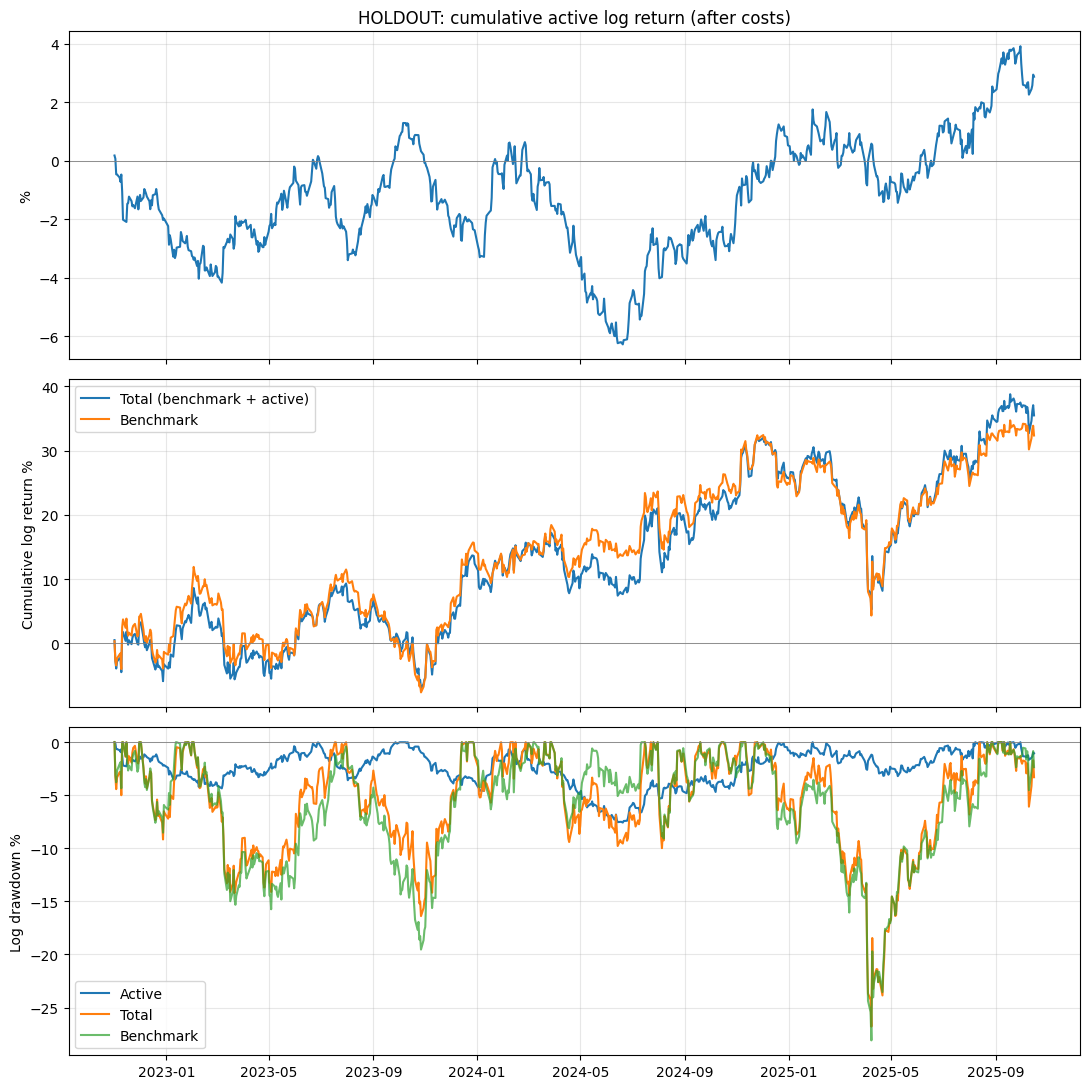

In [16]:
if RUN_HOLDOUT:
    ho = {mi: p for mi, p in positions["Strategy"].items() if me[mi] + 1 + LAG >= hold_idx - 21}
    a2, b2, d2, f2, to2 = backtest(ho, len(dates))
    keep = d2 >= np.datetime64(HOLDOUT_START)
    HSUM = summary(a2[keep], b2[keep], f2[keep], to2).to_frame("HOLDOUT Nov 2022 onward")
    display(pd.concat([SUM, HSUM], axis=1))
    HY = yearly(a2[keep], b2[keep], d2[keep]); display(HY)
    pd.concat([SUM, HSUM], axis=1).to_csv("results/summary_with_holdout.csv"); HY.to_csv("results/yearly_holdout.csv")
    charts(a2[keep], b2[keep], d2[keep], "HOLDOUT", "results/charts_holdout.png")
else:
    print("Holdout sealed. Set RUN_HOLDOUT = True once the team has agreed on the final version.")

**Reading the holdout.** Over November 2022 to October 2025, data never used for any decision, the strategy kept its edge in the same direction:
- **+1.1% a year** of active return after costs, with tracking error of 4.9%: an **information ratio of 0.22** (t = 0.4).
- A worst active drawdown of −7.6% (log), and beta of 0.98.
- By year: Nov–Dec 2022 −2.0%, 2023 −0.4%, 2024 +2.9%, 2025 (through Oct 16) +2.4%.

The holdout is weaker than the development period (IR 0.43) and not statistically significant on its own. Three years is too short to tell an information ratio of about 0.4 from zero, since the uncertainty is about ±0.6. We read it as consistent with a real but modest edge, smaller than the development estimate. That shrinkage is typical out of sample, and is likely partly due to the ~13 versions tried during development. The strategy was not changed after seeing these results.

## 10 · Limitations and next steps

**Limitations:**
1. **Benchmark weights.** The data has no market caps, so the benchmark is an equal-weighted stand-in rather than the cap-weighted Russell 3000. This changes the benchmark's return, how much room the portfolio has to underweight stocks under long-only, and likely the results. The code accepts real market caps (`MKTCAP_PATH`), and we have requested them.
2. **Statistical strength.** t ≈ 2.0 after about 13 portfolio versions, so the edge is borderline in the development period. The holdout is the honest check.
3. **Uneven over time.** The edge was weak from 2008 to 2014; 2009 was −9% active, during the "junk rally."
4. **Group-level bets.** Part of the return comes from leaning toward whole clusters of related stocks (Section 6). Those bets are deliberate, but they are a risk to monitor.
5. **Simplifications.**
   - Flat 10 bps costs (see the cost sensitivity in Section 5).
   - Active weights held constant within each month.
   - No delisting returns in the data.
   - The 1% position limit is our assumption.
   - The economic mechanism is supported only suggestively by the mechanism test.

**Next steps:**
- Rerun with real market-cap benchmark weights.
- Add sector labels to interpret the HRP clusters.
- Test cost-aware rebalancing at higher cost assumptions.